### Playing around with imputing data


In [3]:
# Data libraries

import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import image as mpimg

# sklearn modules
import sklearn

# Load data  
df_avg = pd.read_csv("csv_files/avg_river_levels.csv")
df_min = pd.read_csv("csv_files/min_river_levels.csv")
df_max = pd.read_csv("csv_files/max_river_levels.csv")
df_locs = pd.read_csv("csv_files/monitoring_locations.csv")

# Load data  

# Merge into one useful dataframe 
id_cols = ['County', 'Station_Name', 'Observation_ID']
date_cols = [c for c in df_avg.columns if c not in id_cols]

def melt_river_data(df, value_name):
    """ Converts wide format (dates as columns) to long format (dates as rows)"""
    melted = df.melt(
        id_vars=id_cols, 
        value_vars=date_cols, 
        var_name='Date', 
        value_name=value_name
    )
    return melted

df_avg_long = melt_river_data(df_avg, 'Avg_Level')
df_min_long = melt_river_data(df_min, 'Min_Level')
df_max_long = melt_river_data(df_max, 'Max_Level')

# Merge long format df_min and long format df_avg
df_combined = pd.merge(
    df_avg_long, 
    df_min_long, 
    on=id_cols + ['Date'],  
    how='outer'             
)

# Then merge result with long format df_max 
df_combined = pd.merge(
    df_combined, 
    df_max_long, 
    on=id_cols + ['Date'], 
    how='outer'
)

# Finally merge with df_locs
df_combined = pd.merge(
    df_combined,
    df_locs,
    on=id_cols,
)


# data in wideform 
dates = pd.to_datetime(df_avg.columns[3:], dayfirst=True)   # dd/mm/yyyy strings
vals = df_avg.iloc[:, 3:].copy()
vals.columns = dates
vals.index = df_avg["Observation_ID"]        # or Station_Name, if it's unique
vals = vals.T                                # rows = dates, columns = stations

# full daily data with NA rows where gaps were 
vals = vals.reindex(pd.date_range(vals.index.min(), vals.index.max(), freq="D")) 

# drop bigoutage days 
good = vals[vals.isna().mean(axis=1) <= 0.5] # compute for each date fraction of stations missing,get rid of dates with more than 50% missing

# drop stations that are missing too much of what's left
miss = good.isna().mean()
keep = miss.index[miss <= 0.1]        
filtered = good[keep]

In [6]:
filtered.head()

Observation_ID,aberdeenshire__bogie-redcraig__obs1,aberdeenshire__dee-grampian-mar-lodge__obs1,aberdeenshire__dee-grampian-park__obs1,aberdeenshire__dee-grampian-polhollick__obs1,aberdeenshire__dee-grampian-woodend__obs1,aberdeenshire__deveron-avochie__obs1,aberdeenshire__deveron-huntly-gs__obs1,aberdeenshire__don-alford__obs1,aberdeenshire__don-culfork__obs1,aberdeenshire__don-haughton__obs1,...,wigtown__bladnoch-low-malzie__obs1,wigtown__cree-newton-stewart__obs1,wigtown__cree-wheeb-bridge__obs1,wigtown__piltanton-burn-barsolus__obs1,wigtown__port-erin-wigtown-tidal-level__obs1,wigtown__port-erin-wigtown__obs2,wigtown__portpatrick-wigtown-tidal-level__obs2,wigtown__portpatrick-wigtown__obs1,wigtown__water-of-luce-airyhemming__obs1,wigtown__water-of-minnoch-minnoch-bridge__obs1
2017-03-31,0.221,1.057,1.045,0.772,0.740,0.284,0.525,0.741,0.065,2.366,...,1.603,2.106,1.047,0.686,NaN,NaN,NaN,NaN,1.181,1.641
2017-04-01,0.221,0.867,1.205,0.695,0.892,0.283,0.522,0.749,0.066,2.376,...,1.338,1.278,0.695,0.569,NaN,NaN,NaN,NaN,0.700,0.918
2017-04-02,0.220,0.811,1.087,0.598,0.753,0.283,0.523,0.750,0.074,2.388,...,0.933,0.877,0.561,0.523,NaN,NaN,NaN,NaN,0.553,0.706
2017-04-03,0.212,0.747,0.990,0.535,0.681,0.277,0.517,0.736,0.062,2.364,...,0.823,0.752,0.498,0.505,NaN,NaN,NaN,NaN,0.500,0.641
2017-04-04,0.208,0.738,0.938,0.514,0.638,0.276,0.516,0.727,0.057,2.349,...,0.800,0.942,0.492,0.494,NaN,NaN,NaN,NaN,0.504,0.816


In [5]:

missing_pct = filtered.isna().mean()
worst_station_name = missing_pct.idxmax()
worst_station_missing_pct = missing_pct.max()

df_impute_practice = df_combined[df_combined['Station_Name'] == worst_station_name].copy()
df_impute_practice.head()

station_series = filtered[worst_station_name]
df_impute_practice = station_series.reset_index()
df_impute_practice = df_impute_practice.rename(columns={'index': 'Date', worst_station_name: 'Avg_Level'})
df_impute_practice.head()

,Date,Avg_Level
0,2017-03-31,0.887
1,2017-04-01,0.619
2,2017-04-02,0.543
3,2017-04-03,0.611
4,2017-04-04,0.669


In [ ]:
df_features = pd.read_csv("df_features.csv")
df_features = df_features.drop(columns = ['County', 'Observation_ID'])
df_features.head()

,Station_Name,Std_Level,Mean_Daily_Range,Std_Daily_Range,Max_Daily_Range,Std_Daily_Change,95th_Daily_Range,Missing_Percent,90th_Daily_Range,Percent_Above_90th,Mean_Absolute_Deviation
0,"Bogie, Redcraig",0.204039,0.054572,0.118065,1.184,0.086810,0.28105,24.777346,0.1390,0.728597,0.146542
1,"Dee (Grampian), Mar Lodge",0.173137,0.124972,0.196497,1.810,0.123038,0.51065,24.914364,0.3303,2.950122,0.129072
2,"Dee (Grampian), Park",0.377590,0.169083,0.298416,5.559,0.213299,0.74000,24.823019,0.4510,5.437424,0.272035
3,"Dee (Grampian), Polhollick",0.212161,0.124043,0.188722,1.850,0.135589,0.51000,24.868691,0.3300,2.583587,0.158629
4,"Dee (Grampian), Woodend",0.298935,0.143885,0.238797,3.560,0.172702,0.60000,24.960037,0.3715,3.956178,0.220981


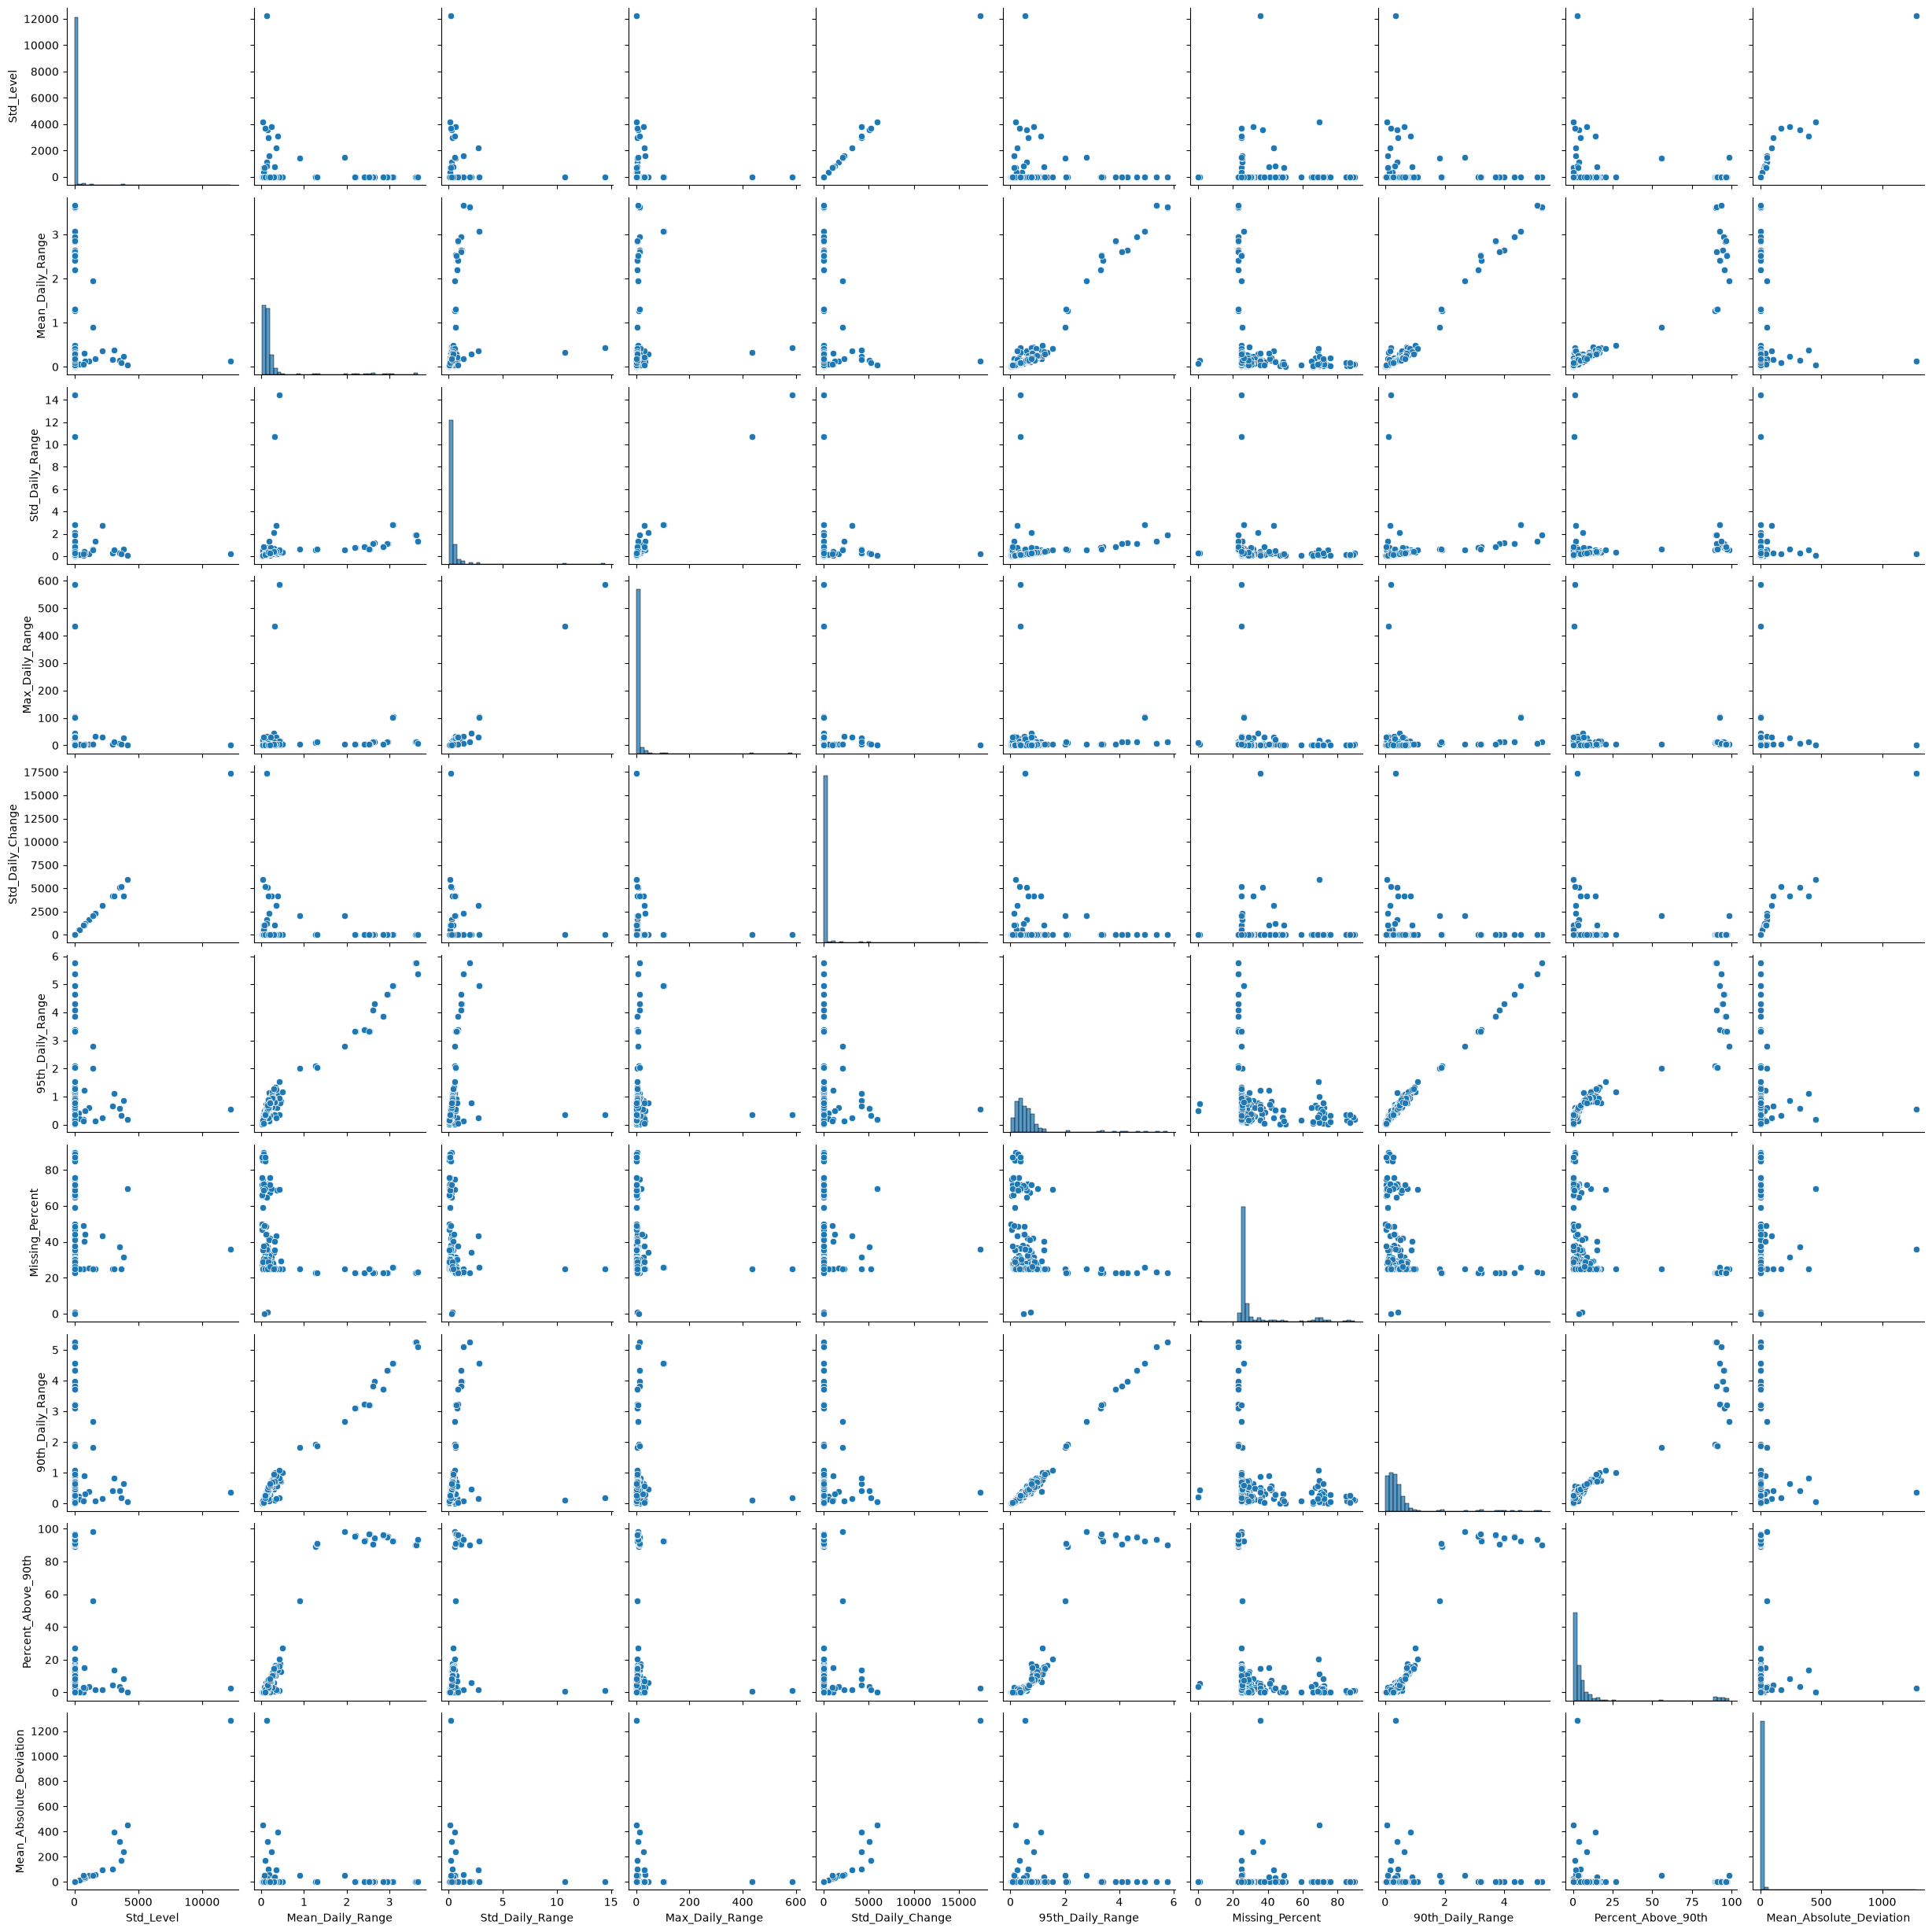

In [20]:
df_visualise = df_features.drop(columns = ['Station_Name'])
sns.pairplot(df_visualise)